In [1]:
import json

import numpy as np
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

annType = ['segm','bbox','keypoints']
annType = annType[2]      #specify type here
prefix = 'person_keypoints' if annType=='keypoints' else 'instances'
print('Running demo for *%s* results.'%(annType))

#initialize COCO ground truth api
dataDir='/home/dev/data/coco/'
dataType='val2017'
annFile = '%s/annotations/%s_%s.json'%(dataDir,prefix,dataType)
cocoGt=COCO(annFile)

Running demo for *keypoints* results.
loading annotations into memory...
Done (t=0.13s)
creating index...
index created!


In [23]:
from PIL import Image
from IPython.display import display

from contextlib import redirect_stdout

%matplotlib inline
import torch
from matplotlib import pyplot as plt
from torchvision.io import read_image
from torchvision.transforms.v2 import ToPILImage
from torchvision.utils import draw_keypoints

to_pil = ToPILImage()

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

connectivity = [[15, 13], [13, 11], [16, 14], [14, 12], [11, 12], [5, 11],
                [6, 12], [5, 6], [5, 7], [6, 8], [7, 9], [8, 10], [1, 2],
                [0, 1], [0, 2], [1, 3], [2, 4], [3, 5], [4, 6]]

In [3]:
print(len(cocoGt.imgs))
print(list(cocoGt.imgs.keys())[:10])

5000
[397133, 37777, 252219, 87038, 174482, 403385, 6818, 480985, 458054, 331352]


In [4]:
annFile

'/home/dev/data/coco//annotations/person_keypoints_val2017.json'

In [5]:
gt = json.load(open(annFile))
gt.keys()

dict_keys(['info', 'licenses', 'images', 'annotations', 'categories'])

# 특정 이미지 하나에 대해 전체 정답을 가져와서 (1)그려보고 (2)평가해서 AP 확인

## 그려보기

In [6]:
gt_sample = []
image_id = 252219

for _ann in gt['annotations']:
    if _ann['image_id'] == image_id:
        gt_sample.append({'image_id': _ann['image_id'], 'category_id': 1, 'score': 1.0, 'keypoints': _ann['keypoints']})

print("size:", lgoen(gt_sample))
print(gt_sample)

size: 3
[{'image_id': 252219, 'category_id': 1, 'score': 1.0, 'keypoints': [356, 198, 2, 358, 193, 2, 351, 194, 2, 364, 192, 2, 346, 194, 2, 375, 207, 2, 341, 211, 2, 388, 236, 2, 336, 238, 2, 392, 263, 2, 343, 242, 2, 373, 271, 2, 347, 272, 2, 372, 316, 2, 348, 318, 2, 372, 353, 2, 355, 354, 2]}, {'image_id': 252219, 'category_id': 1, 'score': 1.0, 'keypoints': [100, 190, 2, 0, 0, 0, 96, 185, 2, 0, 0, 0, 86, 188, 2, 84, 208, 2, 71, 208, 2, 84, 245, 2, 59, 240, 2, 115, 263, 2, 66, 271, 2, 64, 268, 2, 71, 264, 2, 59, 324, 2, 99, 322, 2, 18, 363, 2, 101, 377, 2]}, {'image_id': 252219, 'category_id': 1, 'score': 1.0, 'keypoints': [536, 192, 1, 538, 188, 2, 0, 0, 0, 552, 190, 2, 0, 0, 0, 568, 207, 2, 555, 208, 2, 559, 243, 2, 554, 246, 2, 542, 270, 2, 550, 277, 2, 573, 274, 2, 559, 274, 2, 589, 323, 2, 541, 322, 2, 617, 365, 2, 530, 361, 2]}]


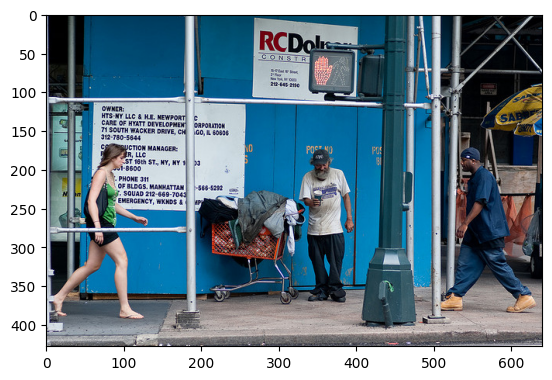

In [7]:
fname = str(image_id).zfill(12)
image_path = f"/home/dev/pose/data/coco/images/val2017/{fname}.jpg"

img = read_image(image_path)
plt_img = to_pil(img)

plt.imshow(plt_img)
plt.show()

In [8]:
num_samples = len(gt_sample)
kps = torch.zeros(num_samples, 17, 2)
vis = torch.zeros(num_samples, 17)

for i in range(num_samples):
    _ann = torch.tensor(gt_sample[i]['keypoints']).reshape(17,3)
    kps[i] = _ann[:,0:2]
    vis[i] = _ann[:,2]

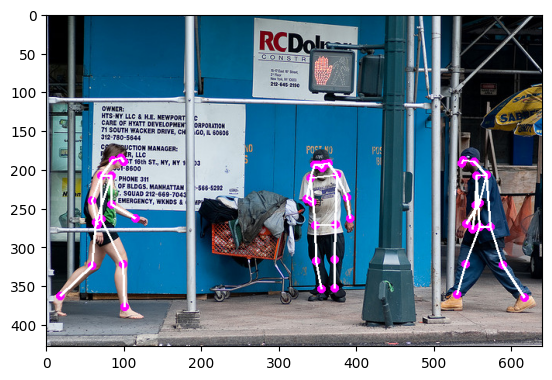

In [9]:
img = read_image(image_path)
img = draw_keypoints(img, kps, connectivity=connectivity, colors=COLOR_MAGENTA, radius=5, visibility=vis)

img = to_pil(img)
plt.imshow(img)
plt.show()

## AP 평가 (gt로 예측 결과 만들어서)

In [10]:
gt_sample_file = f"gt_sample_{image_id}.json"
with open(gt_sample_file, 'w') as fout:
    fout.write(json.dumps(gt_sample))

cocoDt=cocoGt.loadRes(gt_sample_file)

# running evaluation
cocoEval = COCOeval(cocoGt,cocoDt,annType)
# cocoEval.params.imgIds = list(cocoGt.imgs.keys())
cocoEval.params.imgIds = [image_id]
cocoEval.evaluate()
cocoEval.accumulate()
cocoEval.summarize()

Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *keypoints*
DONE (t=0.00s).
Accumulating evaluation results...
DONE (t=0.00s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets= 20 ] = 1.000
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets= 20 ] = 1.000
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets= 20 ] = 1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets= 20 ] = 1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets= 20 ] = 1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 20 ] = 1.000
 Average Recall     (AR) @[ IoU=0.50      | area=   all | maxDets= 20 ] = 1.000
 Average Recall     (AR) @[ IoU=0.75      | area=   all | maxDets= 20 ] = 1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=medium | maxDets= 20 ] = 1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= large | maxDe

In [11]:
cocoEval.stats[0] # AP

np.float64(1.0)

### 얼레? 이렇게 하니까 AP 100% 나오네? 🤔🤔🤔

흠...

# 앞에서부터 하나씩...

넣어보고 AP 측정 해보는 수밖에..

In [28]:
def check(cocoGt, image_id):
    gt_sample = []
    
    for _ann in gt['annotations']:
        if _ann['image_id'] == image_id:
            gt_sample.append({'image_id': _ann['image_id'], 'category_id': 1, 'score': 1.0, 'keypoints': _ann['keypoints']})

    num_samples = len(gt_sample)
    kps = torch.zeros(num_samples, 17, 2)
    vis = torch.zeros(num_samples, 17)
    
    for i in range(num_samples):
        _ann = torch.tensor(gt_sample[i]['keypoints']).reshape(17,3)
        kps[i] = _ann[:,0:2]
        vis[i] = _ann[:,2]

    gt_sample_file = "gt_sample.json"
    with open(gt_sample_file, 'w') as fout:
        fout.write(json.dumps(gt_sample))

    with redirect_stdout(None):
        cocoDt=cocoGt.loadRes(gt_sample_file)
    
    # running evaluation
    with redirect_stdout(None):
        cocoEval = COCOeval(cocoGt,cocoDt,'keypoints')
        cocoEval.params.imgIds = [image_id]
        cocoEval.evaluate()
        cocoEval.accumulate()
        cocoEval.summarize()
    return float(cocoEval.stats[0])

In [29]:
check(cocoGt, 252219)

1.0

In [19]:
target_image_ids = set()

for _ann in gt['annotations']:
    if _ann['category_id'] == 1:
        target_image_ids.add(_ann['image_id'])

print("size:", len(target_image_ids))

size: 2693


## AP < 1.0 케이스들

In [40]:
under_ap_1_images = []

for image_id in target_image_ids:
    ap = check(cocoGt, image_id)
    if ap < 0.99:
        under_ap_1_images.append(image_id)

print("size:", len(under_ap_1_images))
print(under_ap_1_images[:10])

size: 711
[327701, 188439, 434204, 319534, 516143, 532530, 131138, 16451, 376900, 507975]


## 다시 그려보자

In [53]:
gt_sample = []
image_id = 327701

for _ann in gt['annotations']:
    # if _ann['image_id'] == image_id and sum(_ann['keypoints']) > 0:   # It's correct!
    if _ann['image_id'] == image_id:
        gt_sample.append({'image_id': _ann['image_id'], 'category_id': 1, 'score': 1.0, 'keypoints': _ann['keypoints']})

print("size:", len(gt_sample))
print(gt_sample)

size: 4
[{'image_id': 327701, 'category_id': 1, 'score': 1.0, 'keypoints': [423, 299, 2, 426, 301, 2, 0, 0, 0, 433, 325, 2, 0, 0, 0, 411, 368, 2, 416, 350, 2, 355, 393, 2, 367, 343, 2, 370, 344, 2, 374, 288, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}, {'image_id': 327701, 'category_id': 1, 'score': 1.0, 'keypoints': [199, 354, 2, 203, 349, 2, 194, 349, 2, 207, 359, 2, 181, 359, 2, 208, 386, 2, 168, 389, 2, 0, 0, 0, 157, 421, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}, {'image_id': 327701, 'category_id': 1, 'score': 1.0, 'keypoints': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}, {'image_id': 327701, 'category_id': 1, 'score': 1.0, 'keypoints': [148, 413, 2, 150, 410, 2, 143, 410, 2, 0, 0, 0, 134, 410, 2, 153, 423, 1, 127, 423, 1, 0, 0, 0, 0, 0, 0, 156, 423, 1, 140, 425, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}]


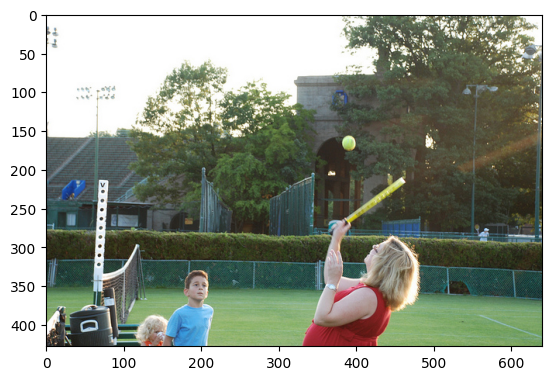

In [50]:
fname = str(image_id).zfill(12)
image_path = f"/home/dev/pose/data/coco/images/val2017/{fname}.jpg"

img = read_image(image_path)
plt_img = to_pil(img)

plt.imshow(plt_img)
plt.show()

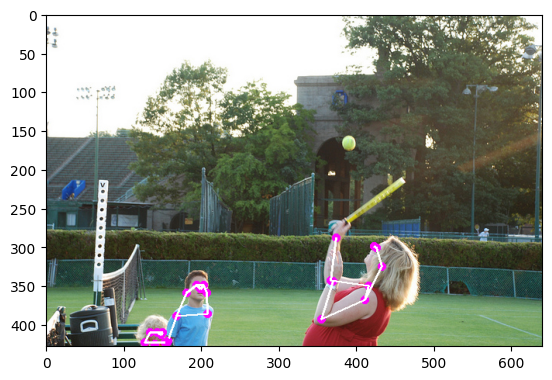

In [51]:
num_samples = len(gt_sample)
kps = torch.zeros(num_samples, 17, 2)
vis = torch.zeros(num_samples, 17)

for i in range(num_samples):
    _ann = torch.tensor(gt_sample[i]['keypoints']).reshape(17,3)
    kps[i] = _ann[:,0:2]
    vis[i] = _ann[:,2]

img = read_image(image_path)
img = draw_keypoints(img, kps, connectivity=connectivity, colors=COLOR_MAGENTA, radius=5, visibility=vis)

img = to_pil(img)
plt.imshow(img)
plt.show()

In [52]:
gt_sample_file = f"gt_sample_{image_id}.json"
with open(gt_sample_file, 'w') as fout:
    fout.write(json.dumps(gt_sample))

cocoDt=cocoGt.loadRes(gt_sample_file)

# running evaluation
cocoEval = COCOeval(cocoGt,cocoDt,annType)
# cocoEval.params.imgIds = list(cocoGt.imgs.keys())
cocoEval.params.imgIds = [image_id]
cocoEval.evaluate()
cocoEval.accumulate()
cocoEval.summarize()

Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *keypoints*
DONE (t=0.00s).
Accumulating evaluation results...
DONE (t=0.00s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets= 20 ] = 0.916
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets= 20 ] = 0.916
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets= 20 ] = 0.916
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets= 20 ] = 1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets= 20 ] = 1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 20 ] = 1.000
 Average Recall     (AR) @[ IoU=0.50      | area=   all | maxDets= 20 ] = 1.000
 Average Recall     (AR) @[ IoU=0.75      | area=   all | maxDets= 20 ] = 1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=medium | maxDets= 20 ] = 1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= large | maxDe

## 결론

너무 작은 사람의 경우 keypoint 값이 전부 0으로 되어 있네. 이 경우를 빼줘야 하네.

```python
if _ann['image_id'] == image_id and sum(_ann['keypoints']) > 0:   # <- 이렇게 해야 함.
if _ann['image_id'] == image_id:                                  # <- 이러면 안 됨.
```